# 01 · Data overview: files, network, availability and quality

What is in the record, whether the tables agree with the files and the OpenSense conventions, where the links are,
how complete they are, and the quality of their data.

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xarray as xr
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve() / "src"))   # the repo's src/
from analysis import v2 as om
DATA = om.setup()                              # D.use('v2'); downloads the record on first run (D.ensure)
meta = om.link_meta()                          # one row per path

## 1. Files and dates

In [2]:
pd.DataFrame([(str(f.relative_to(DATA)), round(f.stat().st_size / 1e6, 2)) for f in sorted(DATA.rglob("*"))
              if f.is_file()], columns=["file", "MB"])

,file,MB
0,README.md,0.02
1,data/links/links_metadata.csv,0.06
2,data/links/openmesh_links.nc,120.06
3,data/weather/asos/asos_stations.csv,0.00
4,data/weather/asos/openmesh_asos.nc,471.33
5,data/weather/ghcn/ghcn_daily.csv,1.04
6,data/weather/ghcn/ghcn_stations.csv,0.00
7,data/weather/radar/openmesh_radar_kokx_rain_20...,0.21
8,data/weather/radar/openmesh_radar_kokx_rain_20...,0.30
9,data/weather/radar/openmesh_radar_kokx_rain_20...,0.24


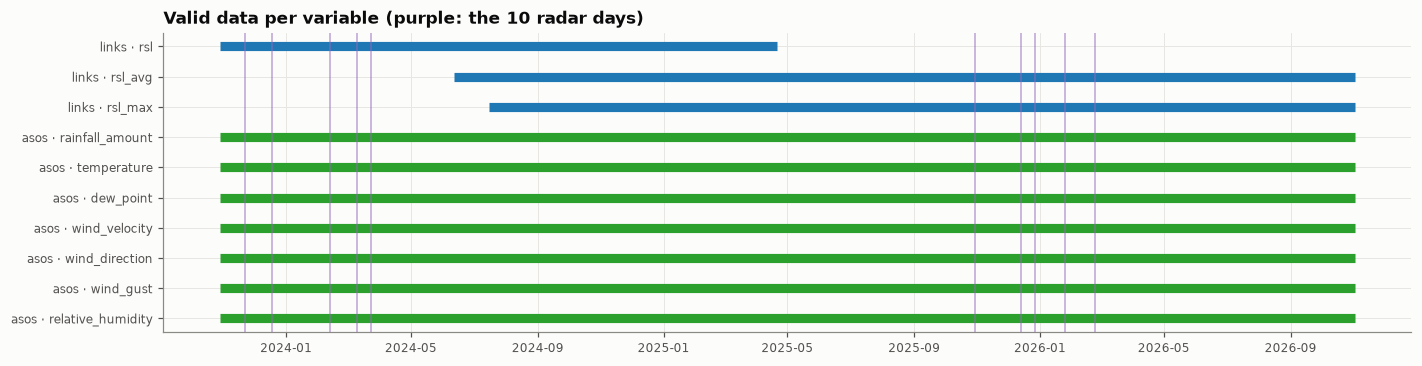

In [3]:
cov = om.plots.valid_periods()

## 2. What each file holds, and how to open it

Every file opens with plain xarray (netCDF) or pandas (CSV); the repo's code is not needed for this.

**Links** (`data/links/openmesh_links.nc`, OpenSense CML): one `cml_id` per path, one `sublink_id` per frequency and
direction. Signals: `rsl` (instantaneous, one per minute, to 2025-04-21), `rsl_avg` and `rsl_max` (over the window
that ends at each stamp; `rsl_max` also in the hour-a-day months). Per sublink: `frequency`, `polarization`; per path:
the two ends, `length`.

In [4]:
links = xr.open_dataset(DATA / "data" / "links" / "openmesh_links.nc")
links

<xarray.Dataset> Size: 9GB
Dimensions:       (cml_id: 378, sublink_id: 4, time: 475518)
Coordinates:
  * cml_id        (cml_id) <U3 5kB '1' '2' '3' '4' ... '375' '376' '377' '378'
    site_0_lat    (cml_id) float64 3kB ...
    site_0_lon    (cml_id) float64 3kB ...
    site_1_lat    (cml_id) float64 3kB ...
    site_1_lon    (cml_id) float64 3kB ...
    length        (cml_id) float64 3kB ...
  * sublink_id    (sublink_id) <U9 144B 'sublink_1' 'sublink_2' ... 'sublink_4'
    frequency     (cml_id, sublink_id) float64 12kB ...
    polarization  (cml_id, sublink_id) <U8 48kB ...
  * time          (time) datetime64[ns] 4MB 2023-10-29 ... 2026-11-01T23:54:00
Data variables:
    site_0_alt    (cml_id) float64 3kB ...
    site_1_alt    (cml_id) float64 3kB ...
    rsl           (cml_id, sublink_id, time) float32 3GB ...
    rsl_avg       (cml_id, sublink_id, time) float32 3GB ...
    rsl_max       (cml_id, sublink_id, time) float32 3GB ...
Attributes:
    title:              OpenMesh: A Continuously Updated Wireless Signal Data...
    file_author:        Dror Jacoby
    institution:        Columbia University (Wireless and Mobile Networking L...
    date:               2026-11-04 14:03:15
    source:             NYC Mesh community wireless network (Ubiquiti radios)...
    version:            2.0.0
    history:            2026-11-04: converted from the NYC Mesh network-manag...
    naming_convention:  OpenSense-1.0
    Conventions:        OpenSense-CML-v1.0
    licence:            CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/)
    reference:          https://doi.org/10.5194/essd-18-5817-2026
    comment:            All timestamps UTC, 2023-10-29 00:00:00 to 2026-11-01...

In [5]:
rows = []
for name in list(links.data_vars) + ["frequency", "length", "polarization"]:
    var = links[name]
    rows.append({"variable": name, "long name": var.attrs.get("long_name", ""), "units": var.attrs.get("units", ""),
                 "dimensions": " x ".join(var.dims)})
pd.DataFrame(rows).set_index("variable")

,long name,units,dimensions
variable,,,
site_0_alt,antenna_altitude_above_sea_level_at_site_0,metres_above_sea,cml_id
site_1_alt,antenna_altitude_above_sea_level_at_site_1,metres_above_sea,cml_id
rsl,received_signal_level,dBm,cml_id x sublink_id x time
rsl_avg,averaged_received_signal_level_over_time_window,dBm,cml_id x sublink_id x time
rsl_max,maximum_received_signal_level_over_time_window,dBm,cml_id x sublink_id x time
frequency,sublink_frequency,MHz,cml_id x sublink_id
length,distance_between_pair_of_antennas,m,cml_id
polarization,sublink_polarization,no units,cml_id x sublink_id


**Rain gauges** (`data/weather/asos/openmesh_asos.nc`, OpenSense PWS): five airport stations, one row per minute. Use
`rainfall_amount` where `rainfall_flag == 0`; `precip_category` is the station's present-weather type.

In [6]:
asos = xr.open_dataset(DATA / "data" / "weather" / "asos" / "openmesh_asos.nc")
rows = []
for name in asos.data_vars:
    var = asos[name]
    rows.append({"variable": name, "long name": var.attrs.get("long_name", ""), "units": var.attrs.get("units", "")})
pd.DataFrame(rows).set_index("variable")

,long name,units
variable,,
rainfall_amount,rainfall_amount_per_time_unit,mm
rainfall_flag,rainfall_plausibility_flag,
temperature,air_temperature,degrees_celsius
dew_point,dew_point_temperature,degrees_celsius
wind_velocity,wind_speed,ms-1
wind_direction,wind_direction,degrees
wind_gust,wind_gust_speed,ms-1
relative_humidity,relative_humidity,%
precip_category,precipitation_category,


**Radar** (`data/weather/radar/openmesh_radar_<kind>_<day>.nc`, one file per day, MRMS on a 0.01° grid): hourly and
15-min rain, and the 10-min precipitation type. `data/weather/radar/radar_events.csv` lists the days.
**Daily gauges** (`data/weather/ghcn/ghcn_daily.csv`): one row per station and day, with the day's window in UTC.

In [7]:
first_radar_file = sorted((DATA / "data" / "weather" / "radar").glob("*.nc"))[0]
radar = xr.open_dataset(first_radar_file)
print(radar)

ghcn = pd.read_csv(DATA / "data" / "weather" / "ghcn" / "ghcn_daily.csv")
ghcn.head(3)

<xarray.Dataset> Size: 3MB
Dimensions:            (time_10min: 145, lat: 45, lon: 59)
Coordinates:
  * time_10min         (time_10min) datetime64[ns] 1kB 2023-11-22 ... 2023-11-23
  * lat                (lat) float64 360B 40.48 40.49 40.51 ... 40.91 40.92
  * lon                (lon) float64 472B -74.27 -74.25 -74.25 ... -73.69 -73.69
Data variables:
    hydrometeor_class  (time_10min, lat, lon) float32 2MB ...
    reflectivity       (time_10min, lat, lon) float32 2MB ...
    scan_time_hhc      (time_10min) datetime64[ns] 1kB ...
    scan_time_n0b      (time_10min) datetime64[ns] 1kB ...
    crs                int32 4B ...
Attributes: (12/15)
    title:              OpenMesh radar example: rain day 2023-11-22 over New ...
    file_author:        Dror Jacoby
    institution:        Cellular Environmental Monitoring (CellEnMon) Lab, Sc...
    source:             NOAA/NWS NEXRAD WSR-88D KOKX (Upton, NY), Level-3 pro...
    licence:            Public domain (NOAA NEXRAD). Credit: NOAA/NWS 

,date,ghcn_id,asos_id,network,day_start_utc,day_end_utc,day_ends,precipitation_mm,snowfall_mm,snow_depth_mm,tmax_c,tmin_c,prcp_mflag,prcp_qflag,prcp_sflag,snow_mflag,snow_qflag,snow_sflag,snwd_mflag,snwd_qflag,snwd_sflag,obs_hhmm
0,2023-10-29,US1NJBG0018,NaN,CoCoRaHS,2023-10-28 11:00,2023-10-29 11:00,"07:00 local time (assumed, CoCoRaHS protocol)",3.0,0.0,0.0,NaN,NaN,NaN,NaN,N,NaN,NaN,N,NaN,NaN,N,NaN
1,2023-10-30,US1NJBG0018,NaN,CoCoRaHS,2023-10-29 11:00,2023-10-30 11:00,"07:00 local time (assumed, CoCoRaHS protocol)",28.2,0.0,0.0,NaN,NaN,NaN,NaN,N,NaN,NaN,N,NaN,NaN,N,NaN
2,2023-10-31,US1NJBG0018,NaN,CoCoRaHS,2023-10-30 11:00,2023-10-31 11:00,"07:00 local time (assumed, CoCoRaHS protocol)",0.0,0.0,0.0,NaN,NaN,T,NaN,N,NaN,NaN,N,NaN,NaN,N,NaN


## 3. The raw series of a few days

Every value the file holds for one path and a few days, without any processing: each sublink, each signal. Below,
the rain and the temperature at the nearest airport gauge. Set the path and the days, then run the next cells.

In [8]:
# ---- choose ----
CML = "6"                                  # a path, "1" to "378"
START, END = "2024-03-22", "2024-03-25"    # UTC

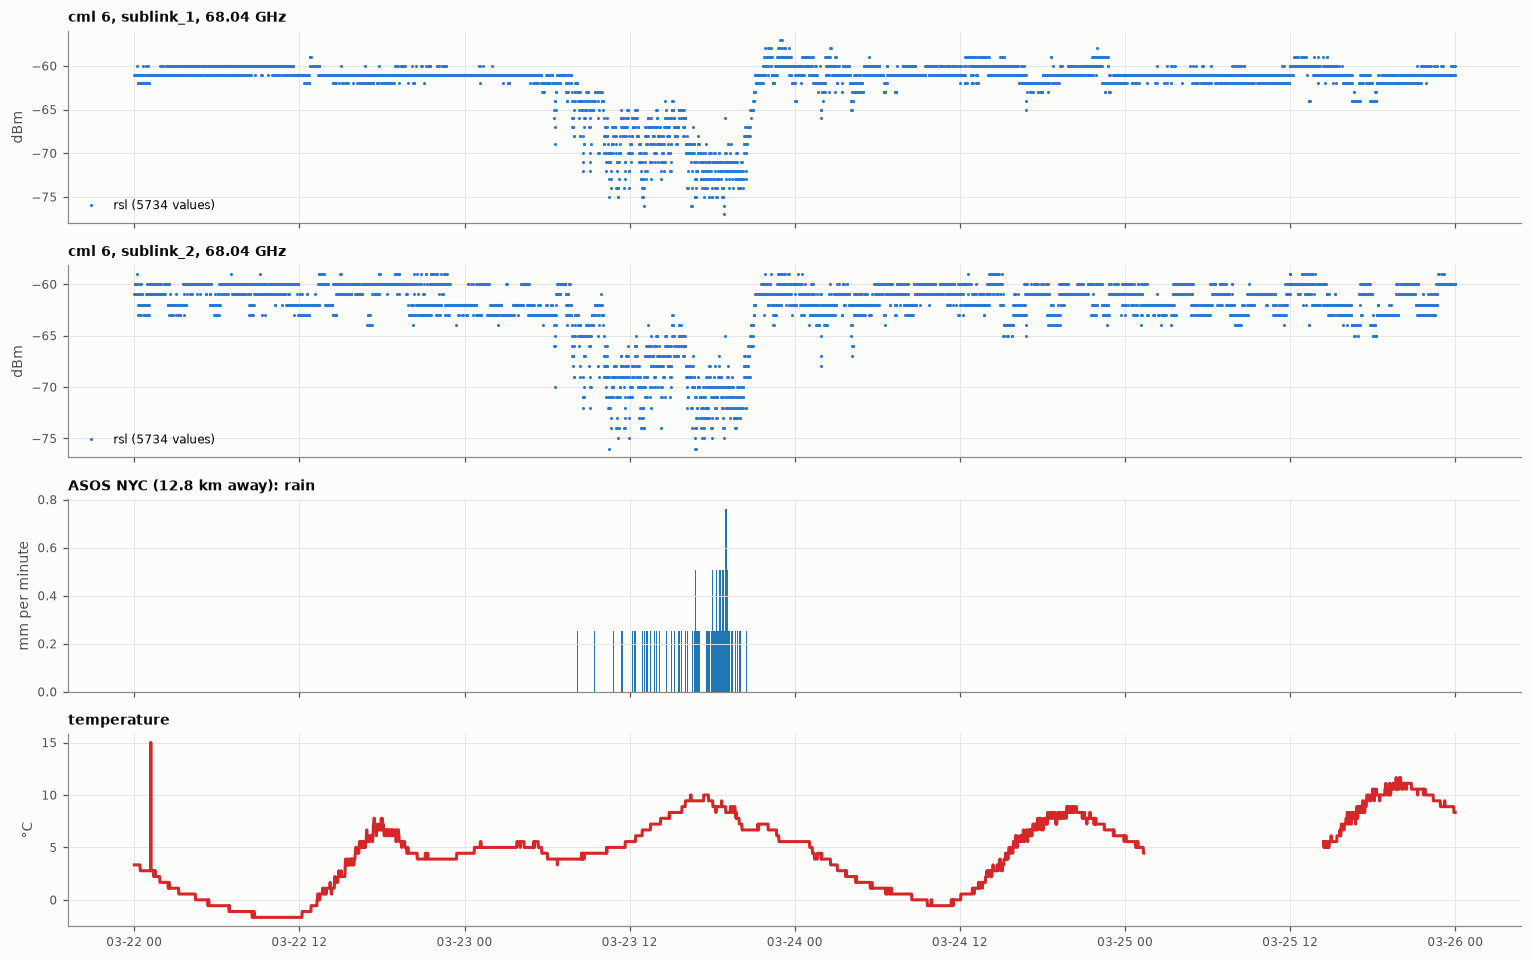

In [9]:
path = links.sel(cml_id=CML, time=slice(START, END))
used_sublinks = [s for s in path.sublink_id.values if np.isfinite(float(path.frequency.sel(sublink_id=s)))]

# The ASOS gauge nearest to the middle of the path
path_lat = float(path.site_0_lat + path.site_1_lat) / 2
path_lon = float(path.site_0_lon + path.site_1_lon) / 2
km_per_degree = 111.0                                   # one degree of latitude; longitude shrinks with cos(latitude)
distance_km = km_per_degree * np.hypot(asos.lat - path_lat, (asos.lon - path_lon) * np.cos(np.radians(path_lat)))
station = str(distance_km.idxmin("id").values)
gauge = asos.sel(id=station, time=slice(START, END))
rain_mm = gauge.rainfall_amount.where(gauge.rainfall_flag == 0)    # usable minutes only

# One panel per sublink with every signal it holds, then the gauge's rain and temperature
n_panels = len(used_sublinks) + 2
fig, axes = plt.subplots(n_panels, 1, figsize=(14, 2.2 * n_panels), sharex=True)
for ax, sublink in zip(axes, used_sublinks):
    one = path.sel(sublink_id=sublink)
    for signal in ["rsl", "rsl_avg", "rsl_max"]:
        n_values = int(one[signal].notnull().sum())
        if n_values > 0:
            ax.plot(one.time, one[signal], ".", markersize=2, label=f"{signal} ({n_values} values)")
    ghz = float(one.frequency) / 1000
    ax.set_title(f"cml {CML}, {sublink}, {ghz:.2f} GHz", fontsize=9, loc="left")
    ax.set_ylabel("dBm")
    ax.legend(fontsize=8, loc="lower left")

ax_rain, ax_temp = axes[-2], axes[-1]
ax_rain.bar(rain_mm.time, rain_mm, width=pd.Timedelta("1min"), color="tab:blue")
ax_rain.set_ylabel("mm per minute")
ax_rain.set_title(f"ASOS {station} ({float(distance_km.min()):.1f} km away): rain", fontsize=9, loc="left")
ax_temp.plot(gauge.time, gauge.temperature, color="tab:red")
ax_temp.set_ylabel("°C")
ax_temp.set_title("temperature", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 4. Sampling

One row per minute to 2025-04-21, then one per poll (hourly to 2025-07, hourly or 6 min from 2025-08, 6 min from 2026-02). `rsl_avg` and
`rsl_max` cover the window from the previous row to this one, except on the hourly days from 2025-08-31 to
2026-01-17, where the values match the hour after the stamp (the record's README.md, "How the link data is sampled").

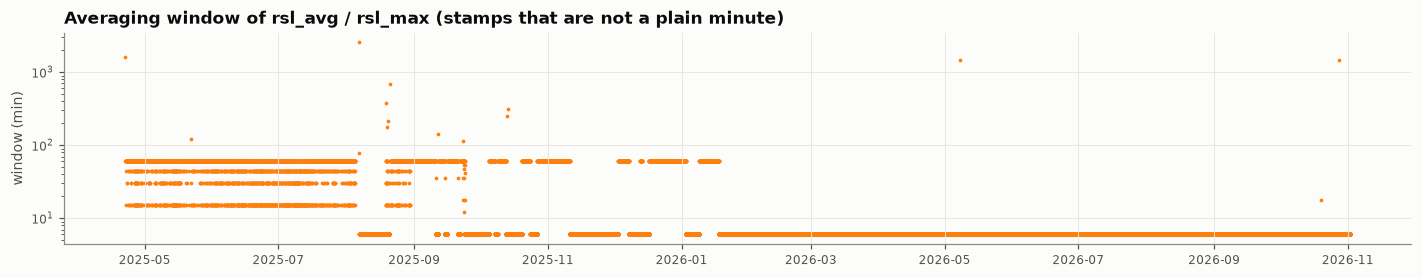

,stamps,usual step (min)
2023-10 → 2024-07,367905,1.0
2024-07 → 2025-04 (1 h a day),15985,1.0
2025-04 → 2025-08,3208,60.0
2025-08 →,51703,6.0


In [10]:
om.plots.windows()

## 5. The tables against the files, and the OpenSense conventions

`om.checks.convention("links")` and `om.checks.convention("asos")` give the variable-by-variable detail.

In [11]:
om.checks.record()

,result,detail
check,,
links_metadata.csv = netCDF: ends,PASS,772 of 772 sublinks
links_metadata.csv = netCDF: frequency,PASS,772 of 772 sublinks
links_metadata.csv = netCDF: length,PASS,772 of 772 sublinks
links_metadata.csv = netCDF: polarization,PASS,772 of 772 sublinks
frequency set exactly on the sublinks of the table,PASS,772 sublinks
"every sublink of the table has values, no other slot has any",PASS,
"no empty position, length or frequency",PASS,
time axis sorted and unique,PASS,"475,518 stamps"
"OpenSense CML: required variables, units, long names",PASS,15 of 15 spec variables present


## 6. Directional links: counts, locations and lengths

In [12]:
from importlib import reload
reload(om.plots)
om.plots.network_table(meta)

,directional links,paths,f min (GHz),f max (GHz),sites,median length (m),shortest (m),longest (m),paths with another band
V60 upper (64–70 GHz),72,36,64.80,69.12,38,1288,397,4352,6
V60 lower (58–63 GHz),8,4,58.32,62.64,7,971,624,1284,1
K24 (24 GHz),14,7,24.10,24.20,11,3609,1401,4426,2
C5 (5–6 GHz),678,339,5.29,5.82,364,706,37,4479,7


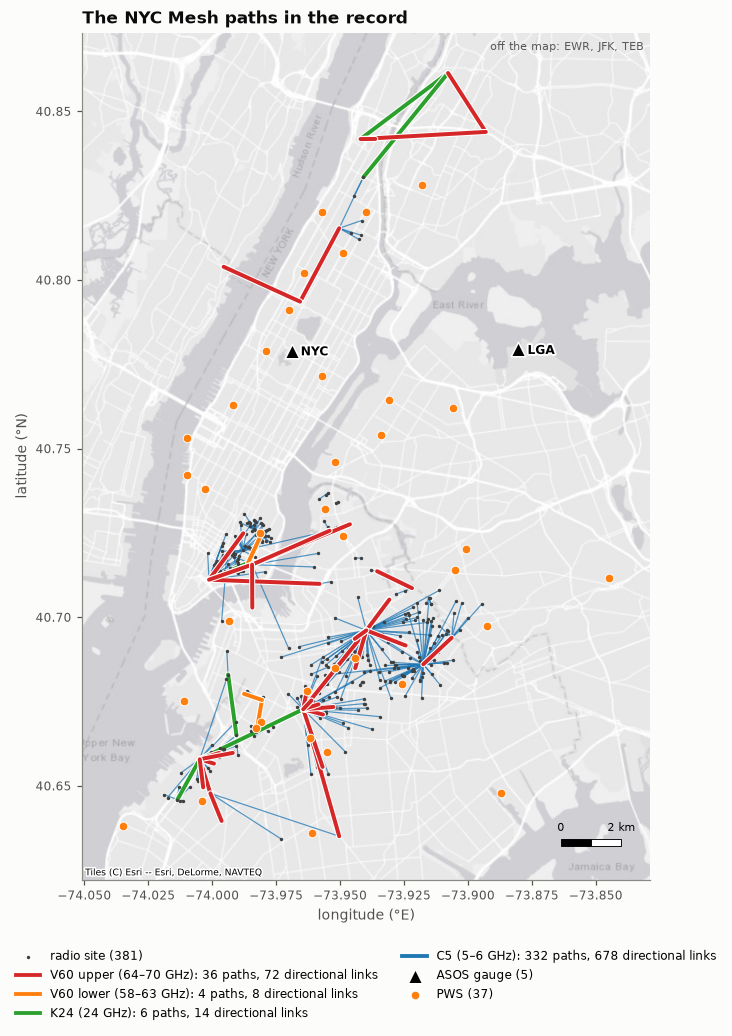

<Axes: title={'left': 'The NYC Mesh paths in the record'}, xlabel='longitude (°E)', ylabel='latitude (°N)'>

In [13]:
# Reload the plotting helpers so edits are picked up in an already-running kernel.
from importlib import reload
reload(om.plots)

PWS = "all"  # "all", a list of station IDs, or False to hide PWS
om.plots.network_map(meta, pws=PWS)

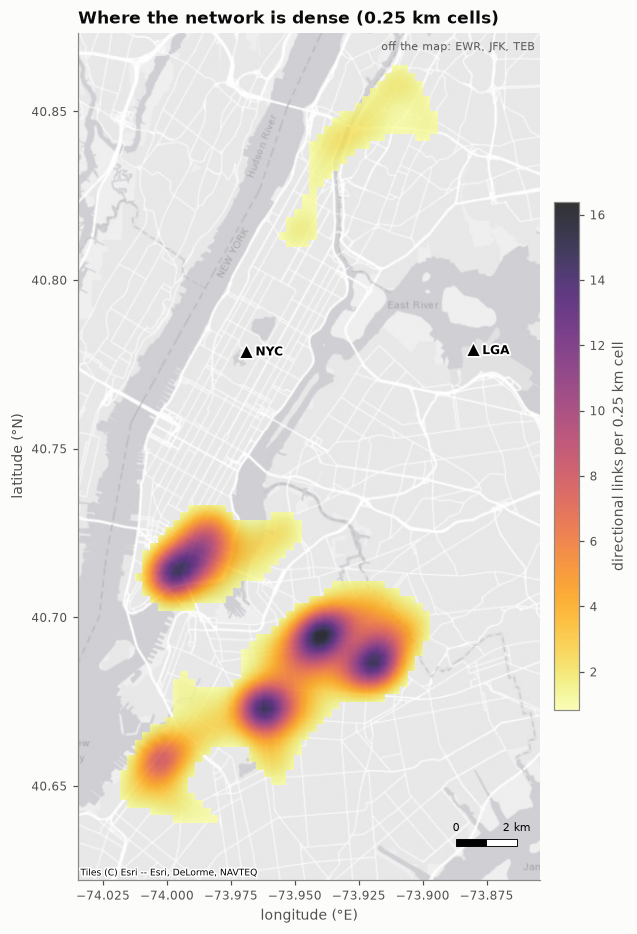

<Axes: title={'left': 'Where the network is dense (0.25 km cells)'}, xlabel='longitude (°E)', ylabel='latitude (°N)'>

In [14]:
om.plots.network_density(meta)

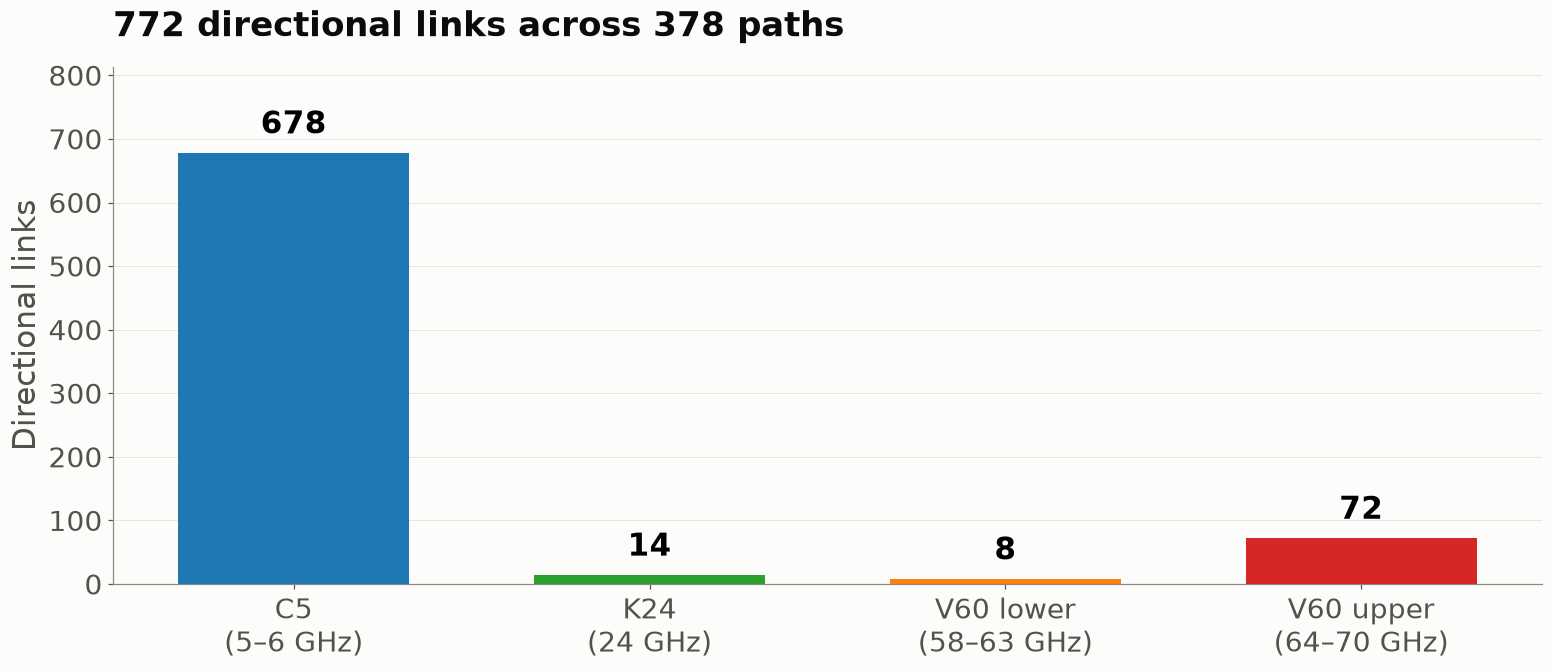

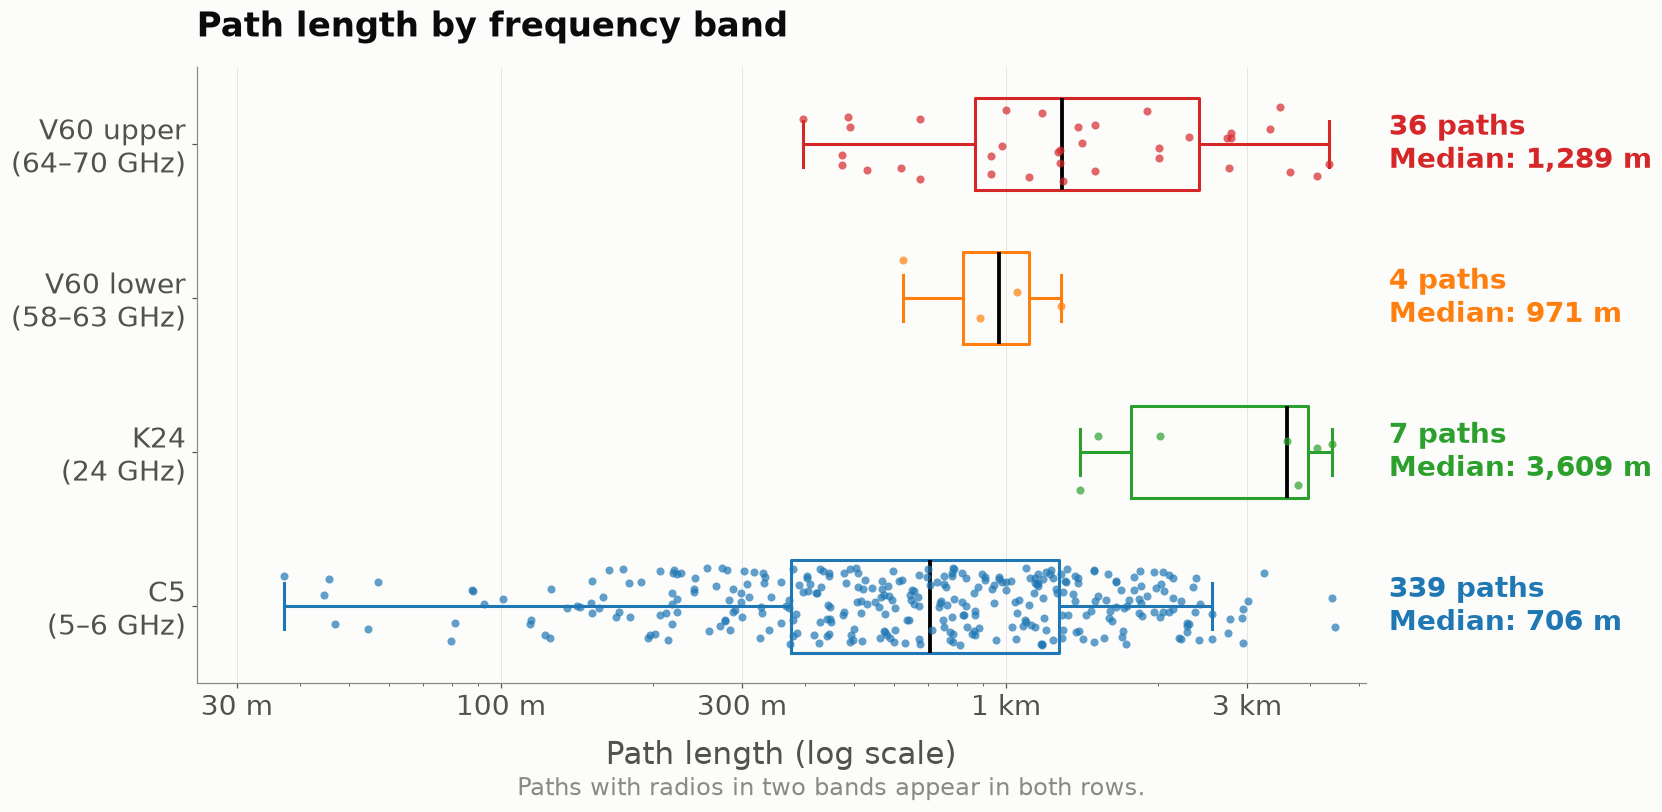

(<Figure size 1540x660 with 1 Axes>, <Figure size 1650x770 with 1 Axes>)

In [15]:
om.plots.link_features(meta)

## 7. Availability

From an hourly summary of the whole links file (`om.hourly()`, a few minutes).

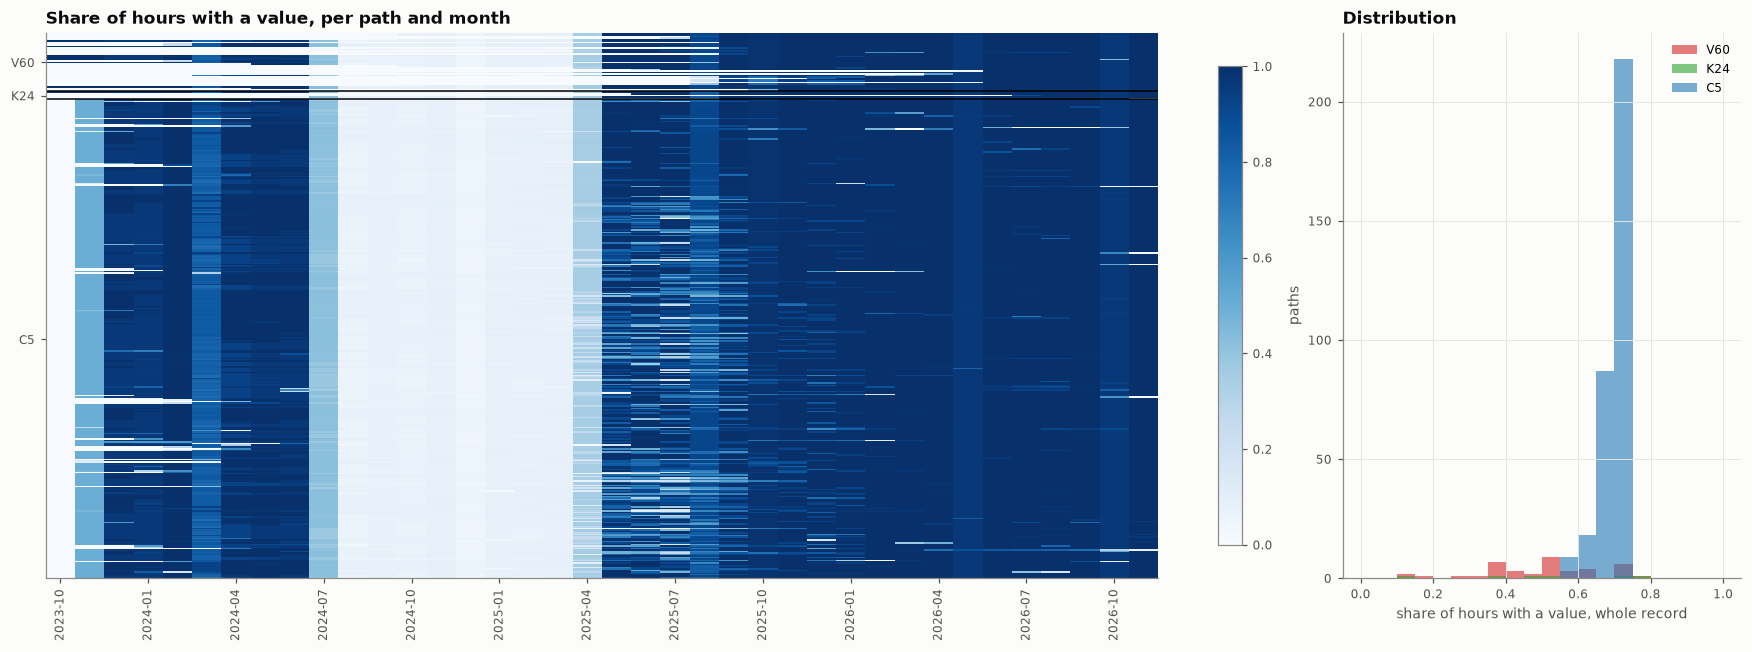

In [16]:
H = om.hourly()
om.plots.availability(meta, H)

## 8. Data quality

**Coverage** per path and day, and the days on which most of the network was silent.

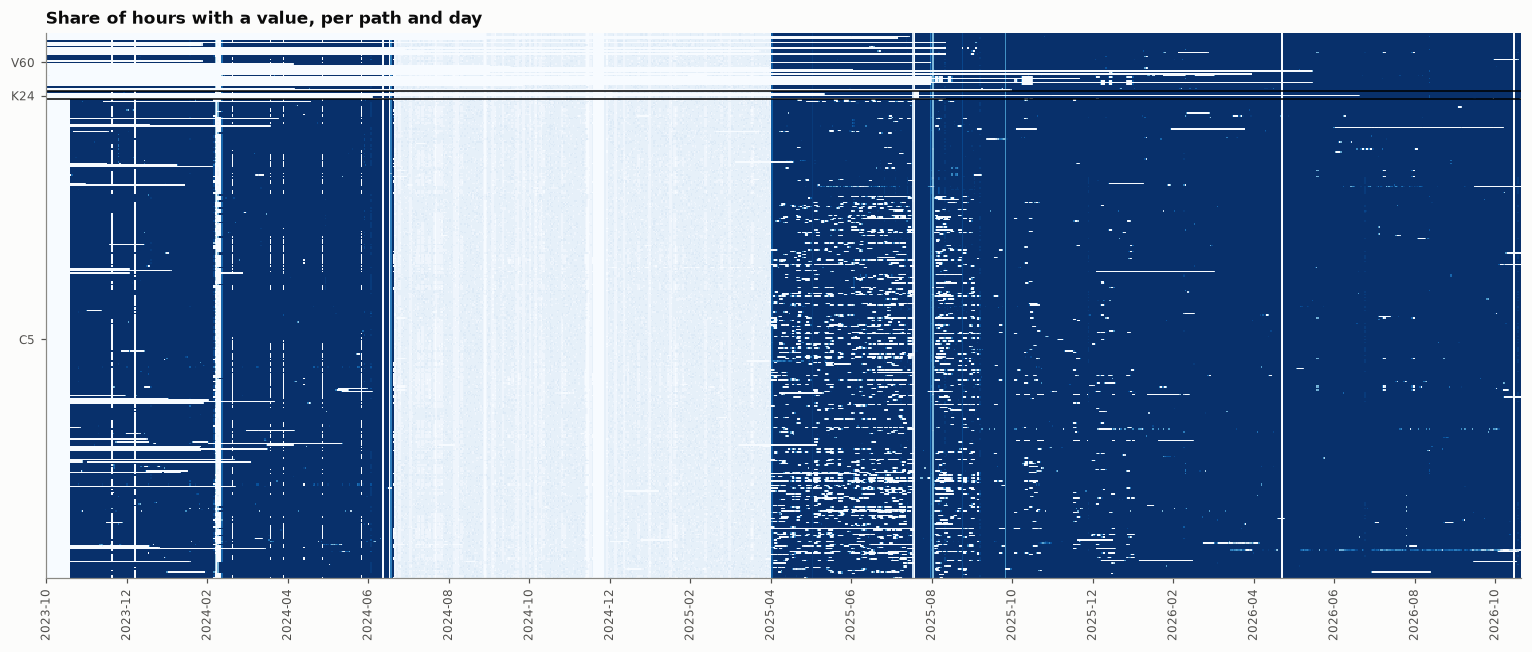

In [17]:
om.quality.coverage(H, meta)

In [18]:
om.quality.outages(H)

,start,end,days
0,2023-10-29,2023-11-15,18
1,2024-12-10,2024-12-17,8
2,2024-03-06,2024-03-07,2
3,2024-01-03,2024-01-03,1
4,2024-03-04,2024-03-04,1
5,2024-07-06,2024-07-06,1
6,2024-07-11,2024-07-11,1
7,2024-09-20,2024-09-20,1


**Levels** per band.

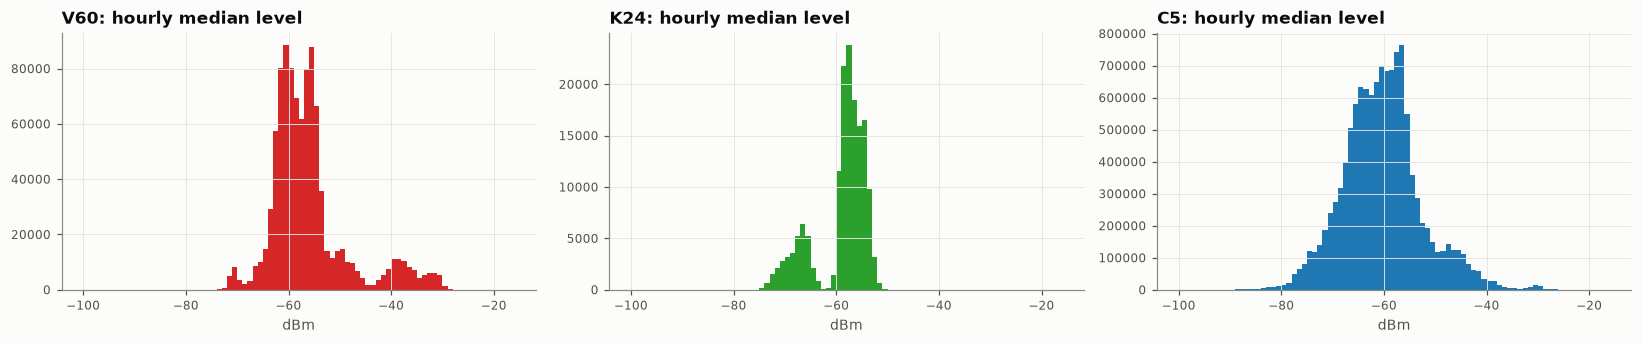

,hours,p01,median,p99
band,,,,
V60,972742,-71.0,-58.0,-32.0
K24,157169,-73.0,-58.0,-53.0
C5,12088053,-78.0,-61.0,-40.0


In [19]:
om.quality.levels(H, meta)

**Anomalies**: five checks on the hourly summary of the whole record. Each row says what is checked, why it matters, how many paths show it and how often. Nothing here is removed from the data (proven frozen reports already are).

In [20]:
anomalies, steps = om.quality.anomalies(H, meta)
anomalies.style.set_properties(**{"text-align": "left", "white-space": "normal"})

,what is checked,why it matters,paths,count,note
check,,,,,
frozen value,sublink_1 repeats one value for 48 h or more,a radio that stopped measuring looks like a perfectly steady dry signal,39,60 runs,"flat in both directions, so kept; proven ones are already removed"
level step,the 7-day median jumps by 6 dB or more,"the dry baseline changes (re-aligned or swapped radio, new obstruction)",152,152 steps,reset the baseline at the step; see the figure below
fast swing,20 dB or more between min and max within one hour (minute data),"rain at 60 GHz, interference at 5 GHz",173,2391 hours,"in rain: V60 70% of 117 h, K24 80% of 5 h, C5 3% of 2269 h"
directions differ,the two directions' medians are 10 dB or more apart,one direction cannot stand in for the other,54,,use each direction on its own
rsl_max below level,the maximum is lower than the level at the same stamp,a consistency check of the file,,0 minutes,0.0000% of all rsl_max
